# Capítulo 5 · Actividad: ¿quién sobrevivió al Titanic?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/01_actividad_titanic_arbol.ipynb)

Entrena un **árbol de decisión** que prediga si un pasajero sobrevivió (`survived`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [5]:
from pathlib import Path

import pandas as pd

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## Importaciones y preparación de datos

In [6]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Asegurar la ruta al dataset (carpeta data/ en la raiz del repositorio)
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

if "df" not in globals():
    df = pd.read_csv(DATA_DIR / "titanic.csv")

# Separar caracteristicas (X) y variable objetivo (y)
# Eliminamos "survived" (target) y "alive" (duplicado directo de survived, evita data leakage)
X = df.drop(columns=["survived", "alive"])
y = df["survived"]

# Division hold-out para la evaluacion final
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "- Test:", X_test.shape)


Train: (712, 13) - Test: (179, 13)


## Configuración del preprocesamiento

In [7]:
# 1. Identificamos columnas numéricas y categóricas
columnas_num = ['age', 'fare', 'sibsp', 'parch']
columnas_cat = ['pclass', 'sex', 'embarked', 'who', 'alone']

# 2. Pipeline numérico: imputamos nulos (como en 'age') con la mediana
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# 3. Pipeline categórico: imputamos nulos con la moda y aplicamos One-Hot Encoding
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 4. Unimos ambos preprocesadores con ColumnTransformer
preprocesador = ColumnTransformer(transformers=[
    ('num', num_transformer, columnas_num),
    ('cat', cat_transformer, columnas_cat)
])

# 5. Pipeline completo: Preprocesamiento + Modelo de Árbol de Decisión
pipeline_arbol = Pipeline([
    ('preprocesamiento', preprocesador),
    ('arbol', DecisionTreeClassifier(random_state=42))
])

print("Pipeline configurado con éxito:")
pipeline_arbol

Pipeline configurado con éxito:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('arbol', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If

## Optimización de Hiperparámetros

In [8]:
# Definimos la rejilla de hiperparámetros a explorar
rejilla = {
    'arbol__criterion': ['gini', 'entropy'],
    'arbol__max_depth': [3, 4, 5, 6, None],
    'arbol__min_samples_split': [2, 5, 10],
    'arbol__min_samples_leaf': [1, 2, 4]
}

# Validación cruzada estratificada (5 folds sobre train)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Búsqueda en cuadrícula
busqueda = GridSearchCV(
    estimator=pipeline_arbol,
    param_grid=rejilla,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Entrenamos solo con el conjunto de entrenamiento
busqueda.fit(X_train, y_train)

print(f"Mejor Accuracy en validación cruzada: {busqueda.best_score_:.4f}\n")
print("Mejores hiperparámetros encontrados:")
for param, valor in busqueda.best_params_.items():
    print(f"  - {param}: {valor}")

Mejor Accuracy en validación cruzada: 0.8161

Mejores hiperparámetros encontrados:
  - arbol__criterion: entropy
  - arbol__max_depth: 3
  - arbol__min_samples_leaf: 1
  - arbol__min_samples_split: 2


## Evaluación en el Conjunto de Prueba

Exactitud (Accuracy) en test: 0.8268
Área bajo la curva ROC (ROC-AUC): 0.8623

Reporte de clasificación:
               precision    recall  f1-score   support

No sobrevivió       0.84      0.89      0.86       110
   Sobrevivió       0.81      0.72      0.76        69

     accuracy                           0.83       179
    macro avg       0.82      0.81      0.81       179
 weighted avg       0.83      0.83      0.82       179



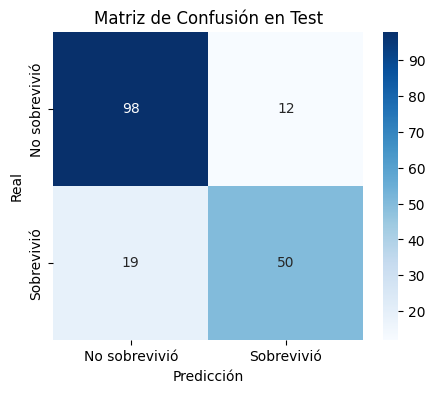

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Seleccionamos el mejor modelo optimizado
mejor_modelo = busqueda.best_estimator_

# Generamos predicciones y probabilidades
y_pred = mejor_modelo.predict(X_test)
y_proba = mejor_modelo.predict_proba(X_test)[:, 1]

# Métricas globales
acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)
print(f"Exactitud (Accuracy) en test: {acc:.4f}")
print(f"Área bajo la curva ROC (ROC-AUC): {auc:.4f}\n")

# Reporte detallado (precisión, recall, f1-score)
print("Reporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=['No sobrevivió', 'Sobrevivió']))

# Matriz de confusión visual
fig, ax = plt.subplots(figsize=(5, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No sobrevivió', 'Sobrevivió'],
            yticklabels=['No sobrevivió', 'Sobrevivió'], ax=ax)
ax.set_xlabel('Predicción')
ax.set_ylabel('Real')
ax.set_title('Matriz de Confusión en Test')
plt.show()

## ¿Qué variables fueron las más importantes?

C:\Users\robof\AppData\Local\Temp\ipykernel_29856\268942603.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_importancias.head(8), x='Importancia', y='Característica', palette='viridis', ax=ax)


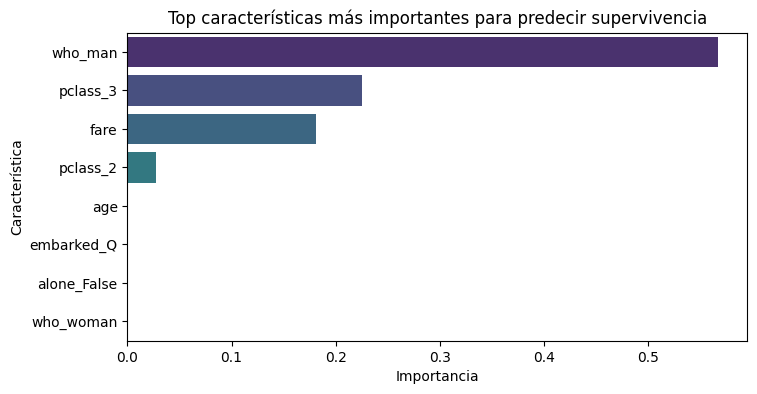

In [10]:
# Nombres de las características luego del OneHotEncoder
nombres_features = mejor_modelo.named_steps['preprocesamiento'].get_feature_names_out()
nombres_limpios = [col.replace('num__', '').replace('cat__', '') for col in nombres_features]

importancias = mejor_modelo.named_steps['arbol'].feature_importances_

df_importancias = pd.DataFrame({
    'Característica': nombres_limpios,
    'Importancia': importancias
}).sort_values('Importancia', ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df_importancias.head(8), x='Importancia', y='Característica', palette='viridis', ax=ax)
ax.set_title('Top características más importantes para predecir supervivencia')
plt.show()